# Quantum Fourier Transform and Quantum Phase Estimation



## QFT
Outline:
1) Write a 3 qubits QFT
2) Write a general n-qubit QFT

In [1]:
import pennylane as qp
import pennylane.numpy as np

Let's build a 3 qubit QFT! The following function allows to create the controlled gates we need: `qp.ctrl(qp.PhaseShift,control=wire)(angle,wire)`

(<Figure size 1100x400 with 1 Axes>, <Axes: >)

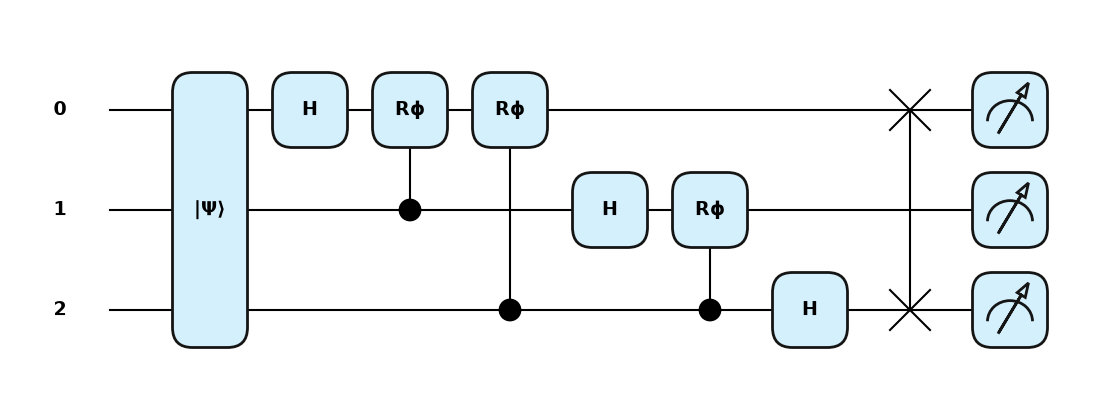

In [2]:
num_qubits = 3
dev = qp.device("default.qubit", wires=num_qubits)

@qp.qnode(dev)
def three_qubit_QFT(basis_id):

    # Initial State Prep
    bits = [int(x) for x in np.binary_repr(basis_id, width=num_qubits)]
    qp.BasisState(bits, wires=range(num_qubits))

    qp.Hadamard(wires=0)
    qp.ctrl(qp.PhaseShift,control=1)(np.pi/2,wires=0)
    qp.ctrl(qp.PhaseShift,control=2)(np.pi/4,wires=0)
    qp.Hadamard(wires=1)
    qp.ctrl(qp.PhaseShift, control=2)(np.pi/2,wires=1)
    qp.Hadamard(wires=2)
    qp.SWAP(wires=[0,2])

    return qp.probs()

qp.draw_mpl(three_qubit_QFT,style = "pennylane")(5)

And now let's implement a general n-qubit version:

In [3]:

def swap_qbits(n_qubits):
    for q in range(int(n_qubits/2)):
        qp.SWAP(wires=[q,n_qubits-q-1])

def qft_rotations(n_qubits):
    # For every wire, add an Hadamard gate and the controlled rotations acting on that wire as a target
    for u in range(n_qubits):
        qp.Hadamard(wires=u)
        for e,v in enumerate(range(u+1,n_qubits)):
            qp.ctrl(qp.PhaseShift,control=v)(np.pi/(2**(e+1)),wires=u)

@qp.qnode(dev) 
def qft_node(basis_id, n_qubits):
    # Prepare the basis state |basis_id>
    bits = [int(x) for x in np.binary_repr(basis_id, width=n_qubits)]
    qp.BasisState(bits, wires=range(n_qubits))
    qft_rotations(n_qubits)
    swap_qbits(n_qubits)
    return qp.state()


(<Figure size 2100x600 with 1 Axes>, <Axes: >)

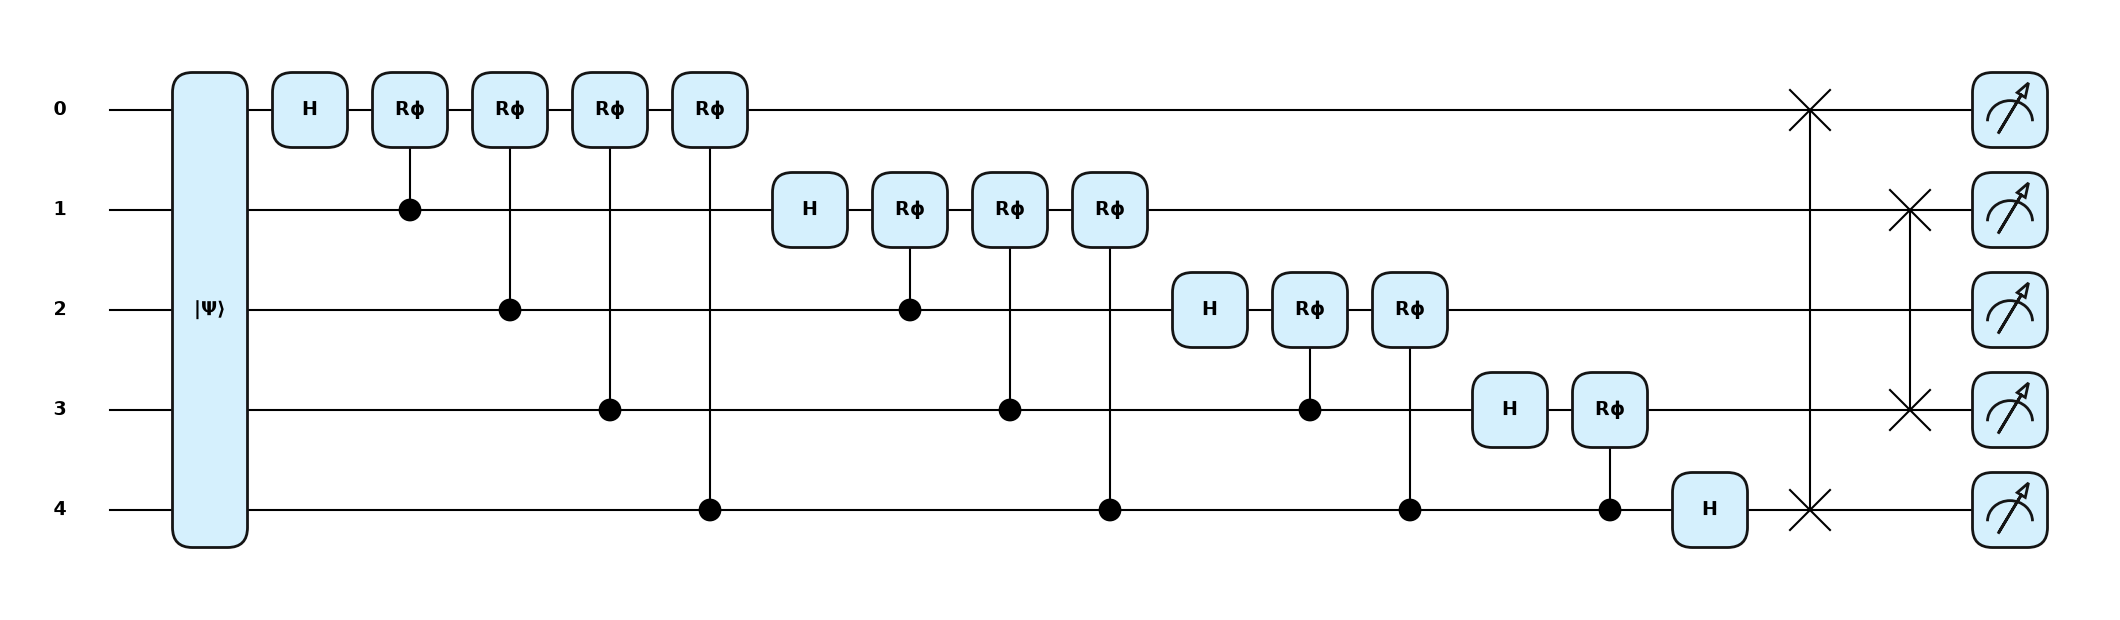

In [4]:
num_qubits=5
basis_id=12
dev = qp.device('default.qubit', wires=num_qubits)
qp.draw_mpl(qft_node,style = "pennylane")(basis_id,num_qubits)

Now we can implement also a recursive version!

In [5]:
def qft_recursive_rotations(n_qubits, wire=0):
    if wire<n_qubits:
        qp.Hadamard(wires=wire)
        for next_qubit in range(wire+1, n_qubits):
            qp.ControlledPhaseShift(np.pi/2**(next_qubit-wire), wires=[next_qubit, wire])
        qft_recursive_rotations(n_qubits,wire+1)

(<Figure size 2100x600 with 1 Axes>, <Axes: >)

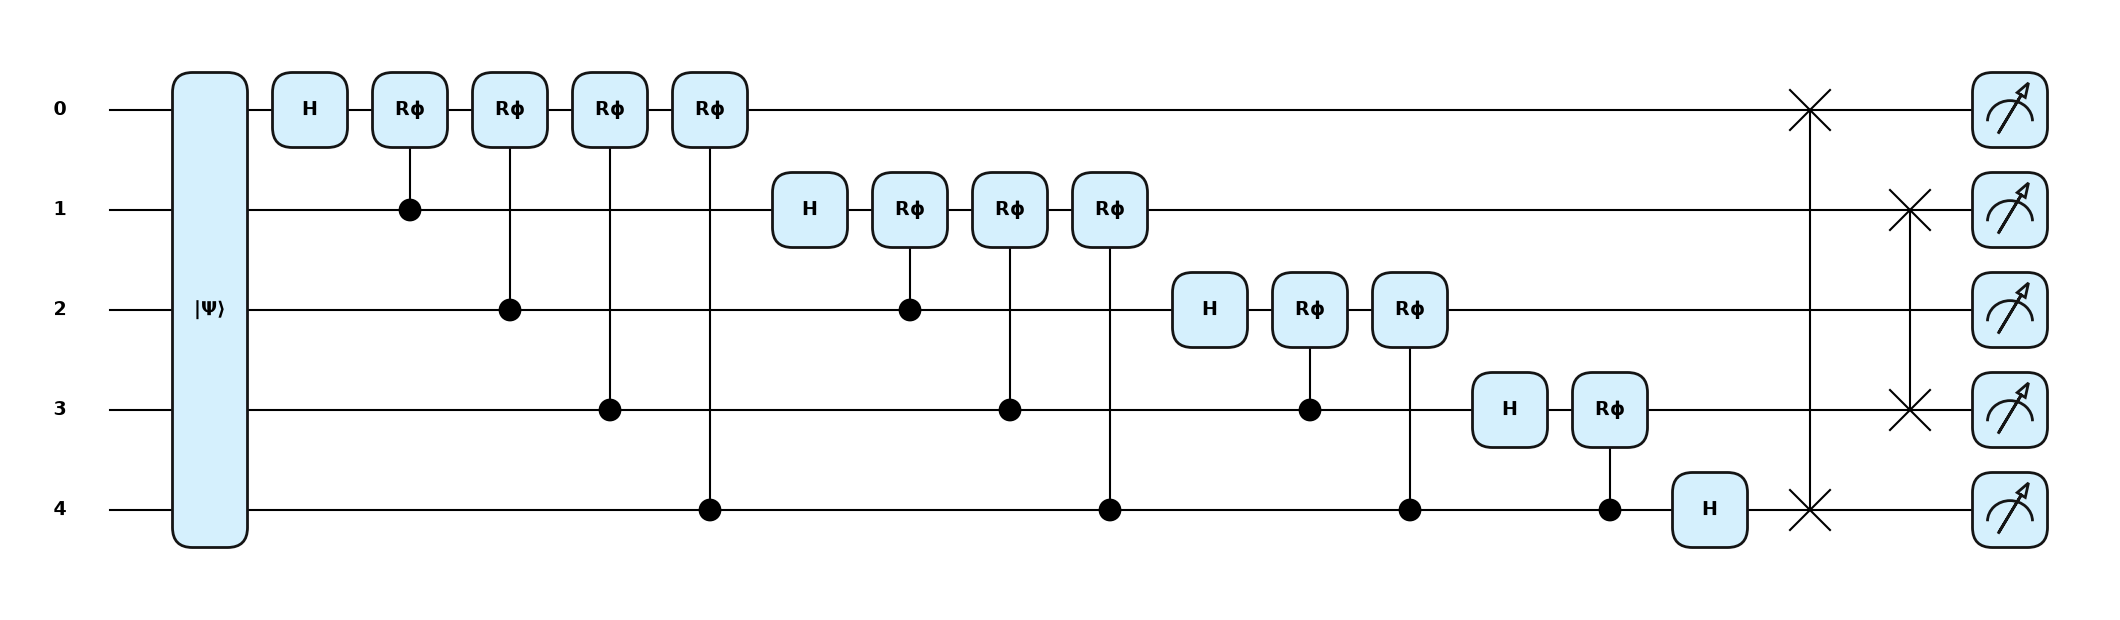

In [6]:
@qp.qnode(dev) 
def qft_node_rec(basis_id, n_qubits):
    # Prepare the basis state |basis_id>
    bits = [int(x) for x in np.binary_repr(basis_id, width=n_qubits)]
    qp.BasisState(bits, wires=range(n_qubits))
    qft_recursive_rotations(n_qubits)
    swap_qbits(n_qubits)
    return qp.state()

num_qubits=5
basis_id=12
dev = qp.device('default.qubit', wires=num_qubits)
qp.draw_mpl(qft_node_rec,style = "pennylane")(basis_id,num_qubits)

There's also the built-in Version: ` qp.QFT`!

## QPE

Let's start with a 3+1 qubit example,  how the controlled unitaries look like?

In [8]:
dev = qp.device("default.qubit", wires=4)

estimation_wires = [0, 1, 2]
target_wires = [3]

As we've already done previously, since we're dealing with a generic unitary, we'll use `qp.ControlledQubitUnitary`

In [10]:
def U_power_2k(unitary, k):
    return np.linalg.matrix_power(unitary,2**k)
    
def apply_controlled_powers_of_U(unitary):
    for k in estimation_wires:
        U = U_power_2k(unitary, len(estimation_wires)-k-1)
        qp.ControlledQubitUnitary(U, wires = [k] + target_wires)

In [11]:
def prepare_eigenvector():
    qp.PauliX(wires=target_wires)

@qp.qnode(dev)
def qpe(unitary):
    prepare_eigenvector()

    for el in estimation_wires:
        qp.Hadamard(wires=el)
    apply_controlled_powers_of_U(unitary)
    qp.adjoint(qp.QFT(wires=estimation_wires))
    
    return qp.probs(wires=estimation_wires)
    
def estimate_phase(probs):
    max_index = np.argmax(probs)
    n = len(probs).bit_length() - 1 
    estimated_phase = max_index / (2**n)
    return estimated_phase

# U is going to be the T gate matrix
U = qp.T.compute_matrix()
probs = qpe(U)

estimated_phase = estimate_phase(probs)
print(estimated_phase)

0.125


(<Figure size 800x500 with 1 Axes>, <Axes: >)

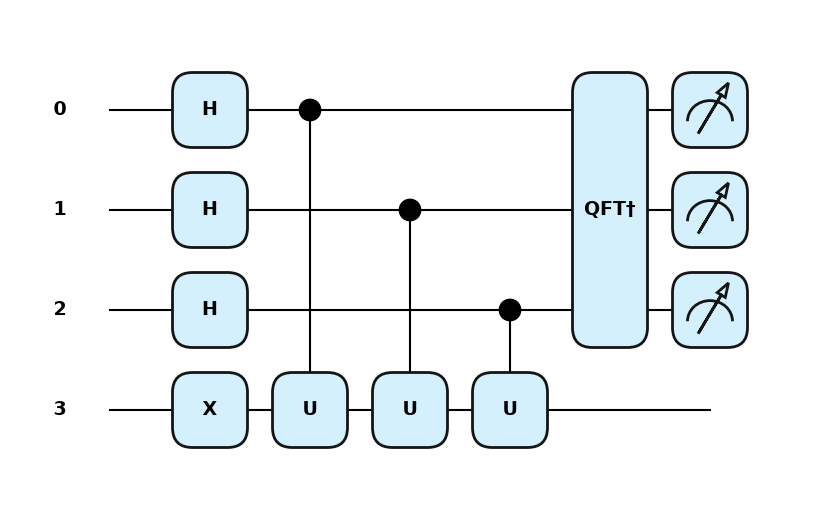

In [12]:
qp.draw_mpl(qpe,style = "pennylane")(U)

Also for QPE Pennylane has a built-in Version: ` qp.QuantumPhaseEstimation`!

## QPE and finding ground states


Let's consider:

$$H = 2I + Z = \begin{pmatrix} 3 & 0 \\ 0 & 1 \end{pmatrix}$$

$H$ is diagonal, so the energies sit on the diagonal and the
eigenvectors are just $|0\rangle$ and $|1\rangle$.

$$H|0\rangle = 3\,|0\rangle \qquad\qquad H|1\rangle = 1\,|1\rangle$$

So the ground state is $|1\rangle$ with **energy 1**.

In [13]:

system_wire = 3           
estimation_wires = [0, 1, 2]   

H = 2 * qp.I(system_wire) + qp.Z(system_wire)

print(qp.matrix(H, wire_order=[system_wire]).real)
print("\neigenvalues:", qp.eigvals(H).real)
print("ground-state energy we are hunting:", qp.eigvals(H).real.min())

[[3. 0.]
 [0. 1.]]

eigenvalues: [1. 3.]
ground-state energy we are hunting: 1.0


###  1. How to choose the time
QPE does not act on $H$. It acts on the unitary

$$U = e^{iHt}$$

which has the **same eigenvectors** but converts each energy into a **phase**:

$$U\,|u_k\rangle = e^{iE_kt}\,|u_k\rangle = e^{2\pi i\varphi_k}\,|u_k\rangle
\qquad\Longrightarrow\qquad \varphi_k = \frac{E_k\,t}{2\pi}$$

QPE measures $\varphi$; we invert that formula to get $E$ back.


Why $t = \pi/4$?

Three estimation qubits can represent phases $m/(2^n)=m/8$ **exactly**, for $m=0,1,\dots,7$. So pick
$t$ to land our phases on exactly those values. Substituting $t = \pi/4$:

$$\varphi = \frac{E\,t}{2\pi} = \frac{E\cdot \pi/4}{2\pi} = \frac{E\cdot\pi}{8\pi} = \frac{E}{8}$$

| eigenstate | energy $E$ | phase $E/8$ | 3-bit binary |
|---|---|---|---|
| $\|1\rangle$ | 1 | $1/8$ | `001` |
| $\|0\rangle$ | 3 | $3/8$ | `011` |


Reading the result:

Invert the phase formula. If the measured bitstring is the integer $m$, then $\varphi = m/8$ and

$$E = \frac{2\pi\varphi}{t} = 8\varphi = 8\cdot\frac{m}{8} = m$$

**The measured integer *is* the energy.** `001` means $E=1$, `011` means $E=3$. No
post-processing.

In [14]:
t = np.pi / 4
U = qp.exp(H, 1j * t)          # U = e^(iHt), as a PennyLane operator

###  2. The three controlled unitaries, by hand

Internally the template applies $U^4$, $U^2$ and $U^1$, each controlled by one estimation
qubit. Because $H$ is diagonal, so are all the powers:

$$U^1 = \begin{pmatrix} e^{3i\pi/4} & 0 \\ 0 & e^{i\pi/4} \end{pmatrix}
\qquad
U^2 = \begin{pmatrix} -i & 0 \\ 0 & i \end{pmatrix}
\qquad
U^4 = \begin{pmatrix} -1 & 0 \\ 0 & -1 \end{pmatrix} = -I$$

### 3.The input and the circuit


$$|\psi\rangle = \mathrm{RY}(\tfrac{2\pi}{3})|0\rangle = \tfrac{1}{2}|0\rangle + \tfrac{\sqrt3}{2}|1\rangle$$


In [15]:
dev = qp.device("default.qubit", wires=4)

@qp.set_shots(2000)
@qp.qnode(dev)
def qpe(theta):
    qp.RY(theta, wires=system_wire)                                  # prepare the input state
    qp.QuantumPhaseEstimation(U, estimation_wires=estimation_wires)       # the whole algorithm
    return qp.counts(wires=estimation_wires)

  bits   energy   count     freq
--------------------------------
   001        1    1518   75.9%
   011        3     482   24.1%

most-sampled bitstring : 001
ground-state energy    : 1
exact answer           : 1


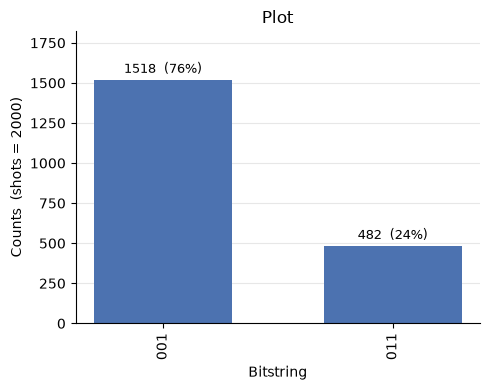

In [16]:
from utils import plot_hist

theta = 2 * np.pi / 3

counts = qpe(theta)
shots = sum(counts.values())

print(f"{'bits':>6}{'energy':>9}{'count':>8}{'freq':>9}")
print("-" * 32)
for bits in sorted(counts, key=counts.get, reverse=True):
    print(f"{bits:>6}{int(bits, 2):>9}{counts[bits]:>8}{counts[bits]/shots:>8.1%}")

winner = max(counts, key=counts.get)
print(f"\nmost-sampled bitstring : {winner}")
print(f"ground-state energy    : {int(winner, 2)}")
print(f"exact answer           : {qp.eigvals(H).real.min():.0f}")


plot_hist(counts)

What is the relation to the coefficients of the input state's superposition and probability of success?


A more concrete example:

In [18]:
system_wires, estimation_wires = [3, 4], [0, 1, 2]

#qp.I(3) adds the constant 4 to every energy. 
#It does nothing physically, since it only shifts the spectrum. 
#It’s there so that every energy lands in 0...7 for our 3-qubit QPE readout

H = qp.X(3) @ qp.X(4) + qp.Y(3) @ qp.Y(4) + qp.Z(3) @ qp.Z(4) + 4 * qp.I(3)
U = qp.exp(H, 1j * np.pi / 4)          

arr=[0,.7,-.1,0]       
psi = np.array(arr) / np.linalg.norm(arr)

@qp.set_shots(4000)
@qp.qnode(qp.device("default.qubit", wires=5))
def qpe():
    qp.StatePrep(psi, wires=system_wires)
    qp.QuantumPhaseEstimation(U, estimation_wires=estimation_wires)
    return qp.counts(wires=estimation_wires)

counts = qpe()
for b in sorted(counts, key=counts.get, reverse=True):
    print(f"{b}   E = {int(b, 2)}   {counts[b] / 4000:.1%}")

print("exact eigenvalues:", np.round(qp.eigvals(H).real))

001   E = 1   64.2%
101   E = 5   35.8%
exact eigenvalues: [1. 5. 5. 5.]


##  How to find a good initial state?

Can use the VQE, try it out!
